In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans, DBSCAN
from sklearn.decomposition import PCA
from sklearn.metrics import silhouette_score
from sklearn.neighbors import NearestNeighbors

sns.set_theme(style="whitegrid")
print("Pustaka klasterisasi K-Means dan DBSCAN berhasil dimuat.")

Pustaka klasterisasi K-Means dan DBSCAN berhasil dimuat.


In [2]:
# Memuat dataset cafe hasil pra-pengolahan Jobsheet 2
path_cafes = '../outputs/cafes_preprocessed.csv'
if not os.path.exists(path_cafes):
    path_cafes = '../dataset/cafes.csv'

df_cafes = pd.read_csv(path_cafes)

# Pastikan fitur harga telah diimputasi
if 'price_min_imputed' not in df_cafes.columns:
    df_cafes['price_min_imputed'] = df_cafes['price_min'].fillna(df_cafes['price_min'].median())
    df_cafes['price_max_imputed'] = df_cafes['price_max'].fillna(df_cafes['price_max'].median())

feature_cols = ['latitude', 'longitude', 'rating', 'review_count', 'price_min_imputed', 'price_max_imputed']
X_raw = df_cafes[feature_cols].copy()

# Standardisasi fitur menggunakan StandardScaler
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X_raw)

print(f"Data Cafe siap diklasterisasi: {X_scaled.shape[0]} baris, {X_scaled.shape[1]} fitur")
print("Fitur yang digunakan:", feature_cols)

Data Cafe siap diklasterisasi: 275 baris, 6 fitur
Fitur yang digunakan: ['latitude', 'longitude', 'rating', 'review_count', 'price_min_imputed', 'price_max_imputed']


Nilai K dengan Silhouette Score Tertinggi: K = 8 (Skor: 0.2700)


<string>:30: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown



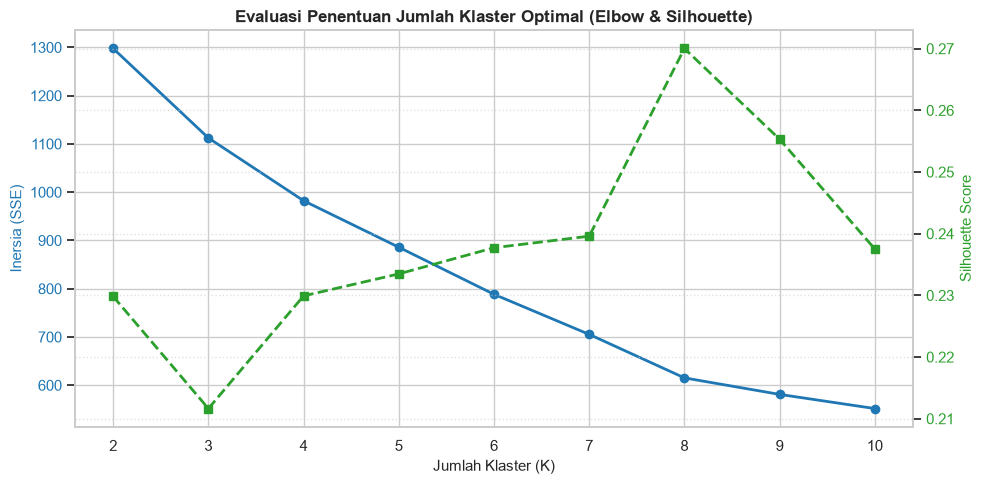

In [3]:
# Eksperimen nilai K dari 2 hingga 10
K_range = range(2, 11)
inertia_list = []
silhouette_list = []

for k in K_range:
    kmeans = KMeans(n_clusters=k, random_state=42, n_init=10)
    labels = kmeans.fit_predict(X_scaled)
    inertia_list.append(kmeans.inertia_)
    silhouette_list.append(silhouette_score(X_scaled, labels))

# Visualisasi Elbow Curve dan Silhouette Score
fig, ax1 = plt.subplots(figsize=(10, 5))

color = 'tab:blue'
ax1.set_xlabel('Jumlah Klaster (K)', fontsize=11)
ax1.set_ylabel('Inersia (SSE)', color=color, fontsize=11)
line1 = ax1.plot(K_range, inertia_list, marker='o', color=color, linewidth=2, label='Inertia (Elbow)')
ax1.tick_params(axis='y', labelcolor=color)

ax2 = ax1.twinx()
color = 'tab:green'
ax2.set_ylabel('Silhouette Score', color=color, fontsize=11)
line2 = ax2.plot(K_range, silhouette_list, marker='s', color=color, linewidth=2, linestyle='--', label='Silhouette Score')
ax2.tick_params(axis='y', labelcolor=color)

plt.title('Evaluasi Penentuan Jumlah Klaster Optimal (Elbow & Silhouette)', fontsize=12, fontweight='bold')
plt.grid(True, linestyle=':', alpha=0.6)
plt.tight_layout()
plt.show()

best_k = K_range[np.argmax(silhouette_list)]
print(f"Nilai K dengan Silhouette Score Tertinggi: K = {best_k} (Skor: {max(silhouette_list):.4f})")
# Untuk segmentasi cafe bisnis yang informatif, K = 3 atau 4 merupakan titik siku ideal

In [4]:
# Melatih K-Means dengan K = 3 (Segmentasi Bisnis: Budget/Komunal, Populer/Keluarga, Premium/Estetik)
k_optimal = 3
kmeans_final = KMeans(n_clusters=k_optimal, random_state=42, n_init=10)
df_cafes['cluster_kmeans'] = kmeans_final.fit_predict(X_scaled)

sil_kmeans = silhouette_score(X_scaled, df_cafes['cluster_kmeans'])
print(f"Silhouette Score K-Means (K={k_optimal}): {sil_kmeans:.4f}")
print("\nDistribusi Jumlah Cafe per Klaster:")
print(df_cafes['cluster_kmeans'].value_counts().sort_index())

# Rata-rata fitur per klaster
profil_cluster = df_cafes.groupby('cluster_kmeans')[feature_cols].mean().round(2)
profil_cluster['jumlah_cafe'] = df_cafes['cluster_kmeans'].value_counts().sort_index()
print("\nProfil Rata-Rata Fitur per Klaster:")
print(profil_cluster[['jumlah_cafe', 'rating', 'review_count', 'price_min_imputed', 'price_max_imputed']])

Silhouette Score K-Means (K=3): 0.2116

Distribusi Jumlah Cafe per Klaster:
cluster_kmeans
0     76
1     67
2    132
Name: count, dtype: int64

Profil Rata-Rata Fitur per Klaster:
                jumlah_cafe  rating  ...  price_min_imputed  price_max_imputed
cluster_kmeans                       ...                                      
0                        76    4.62  ...             158.74            3948.21
1                        67    4.76  ...           10910.93           13433.31
2                       132    4.63  ...           27098.48           35795.45

[3 rows x 5 columns]


<string>:17: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown



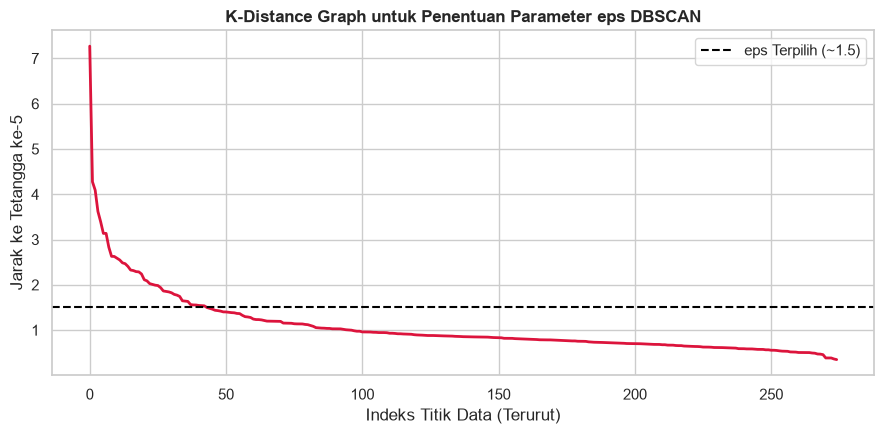

In [5]:
# Menghitung jarak ke k-tetangga terdekat (k = min_samples = 5)
min_samples = 5
nn = NearestNeighbors(n_neighbors=min_samples)
nn.fit(X_scaled)
distances, _ = nn.kneighbors(X_scaled)
k_distances = np.sort(distances[:, -1])[::-1]

# Visualisasi K-Distance Graph
plt.figure(figsize=(9, 4.5))
plt.plot(k_distances, color='crimson', linewidth=2)
plt.title('K-Distance Graph untuk Penentuan Parameter eps DBSCAN', fontsize=12, fontweight='bold')
plt.xlabel('Indeks Titik Data (Terurut)')
plt.ylabel(f'Jarak ke Tetangga ke-{min_samples}')
plt.axhline(y=1.5, color='black', linestyle='--', label='eps Terpilih (~1.5)')
plt.legend()
plt.tight_layout()
plt.show()

In [6]:
# Melatih DBSCAN dengan eps=1.5 dan min_samples=5
eps_val = 1.5
dbscan = DBSCAN(eps=eps_val, min_samples=min_samples)
df_cafes['cluster_dbscan'] = dbscan.fit_predict(X_scaled)

labels_db = df_cafes['cluster_dbscan']
n_clusters_db = len(set(labels_db)) - (1 if -1 in labels_db else 0)
n_noise = (labels_db == -1).sum()

# Hitung silhouette score hanya pada titik non-noise jika terbentuk > 1 klaster
mask_valid = labels_db != -1
if n_clusters_db > 1 and mask_valid.sum() > n_clusters_db:
    sil_dbscan = silhouette_score(X_scaled[mask_valid], labels_db[mask_valid])
else:
    sil_dbscan = 0.0

print(f"Hasil Klasterisasi DBSCAN (eps={eps_val}, min_samples={min_samples}):")
print(f"- Jumlah Klaster Terbentuk : {n_clusters_db}")
print(f"- Jumlah Titik Noise/Pencilan : {n_noise} ({n_noise/len(df_cafes)*100:.2f}%)")
print(f"- Silhouette Score (Non-Noise) : {sil_dbscan:.4f}")
print("\nDistribusi Klaster DBSCAN:")
print(labels_db.value_counts())

Hasil Klasterisasi DBSCAN (eps=1.5, min_samples=5):
- Jumlah Klaster Terbentuk : 3
- Jumlah Titik Noise/Pencilan : 33 (12.00%)
- Silhouette Score (Non-Noise) : 0.2596

Distribusi Klaster DBSCAN:
cluster_dbscan
 1    136
 0    106
-1     33
Name: count, dtype: int64


Variansi dijelaskan oleh PCA: PC1=30.60%, PC2=23.50% (Total: 54.10%)


<string>:42: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown



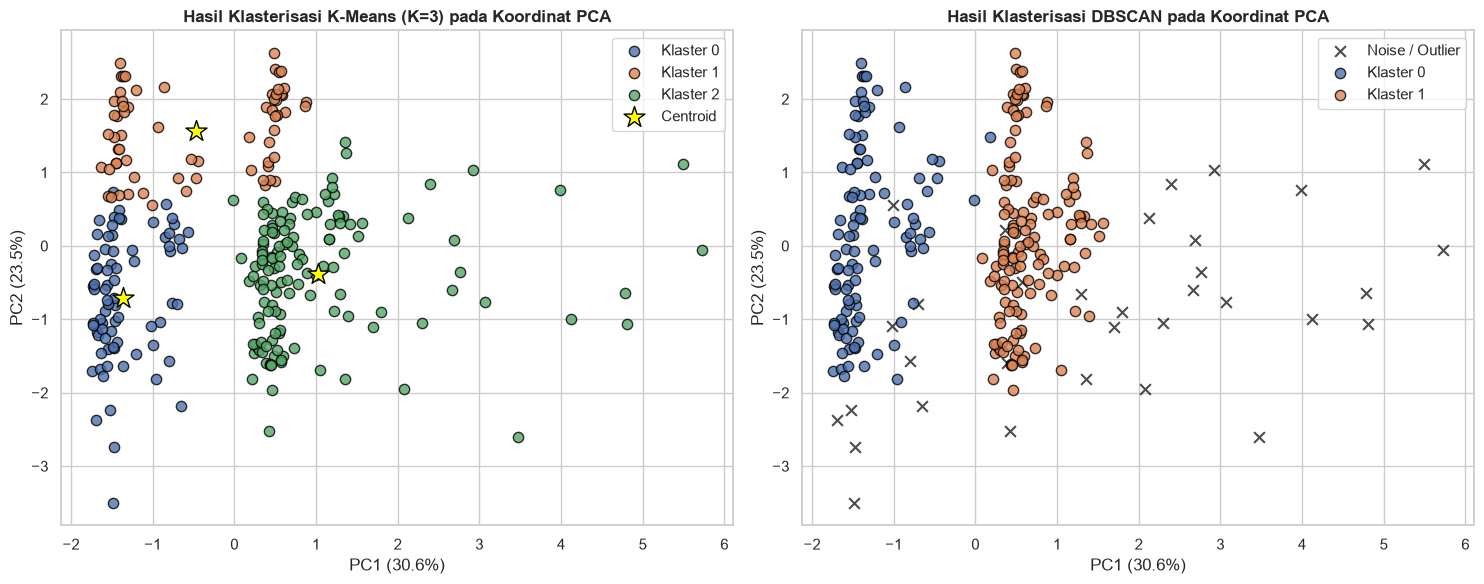

In [7]:
# Reduksi dimensi fitur ke 2 Komponen Utama (PC1 dan PC2)
pca = PCA(n_components=2, random_state=42)
X_pca = pca.fit_transform(X_scaled)
df_cafes['pca1'] = X_pca[:, 0]
df_cafes['pca2'] = X_pca[:, 1]

var_ratio = pca.explained_variance_ratio_ * 100
print(f"Variansi dijelaskan oleh PCA: PC1={var_ratio[0]:.2f}%, PC2={var_ratio[1]:.2f}% (Total: {var_ratio.sum():.2f}%)")

# Visualisasi perbandingan sebaran klaster K-Means vs DBSCAN
plt.figure(figsize=(15, 6))

# Subplot 1: K-Means
plt.subplot(1, 2, 1)
palette_km = ['#3498db', '#e74c3c', '#2ecc71']
for c in sorted(df_cafes['cluster_kmeans'].unique()):
    subset = df_cafes[df_cafes['cluster_kmeans'] == c]
    plt.scatter(subset['pca1'], subset['pca2'], label=f'Klaster {c}', alpha=0.8, edgecolors='black', s=55)

# Centroid K-Means dalam koordinat PCA
centroids_pca = pca.transform(kmeans_final.cluster_centers_)
plt.scatter(centroids_pca[:, 0], centroids_pca[:, 1], marker='*', s=250, color='yellow', edgecolors='black', label='Centroid', zorder=5)
plt.title(f'Hasil Klasterisasi K-Means (K={k_optimal}) pada Koordinat PCA', fontsize=12, fontweight='bold')
plt.xlabel(f'PC1 ({var_ratio[0]:.1f}%)')
plt.ylabel(f'PC2 ({var_ratio[1]:.1f}%)')
plt.legend()

# Subplot 2: DBSCAN
plt.subplot(1, 2, 2)
for c in sorted(df_cafes['cluster_dbscan'].unique()):
    subset = df_cafes[df_cafes['cluster_dbscan'] == c]
    if c == -1:
        plt.scatter(subset['pca1'], subset['pca2'], label='Noise / Outlier', color='black', marker='x', s=60, alpha=0.7)
    else:
        plt.scatter(subset['pca1'], subset['pca2'], label=f'Klaster {c}', alpha=0.8, edgecolors='black', s=55)
plt.title(f'Hasil Klasterisasi DBSCAN pada Koordinat PCA', fontsize=12, fontweight='bold')
plt.xlabel(f'PC1 ({var_ratio[0]:.1f}%)')
plt.ylabel(f'PC2 ({var_ratio[1]:.1f}%)')
plt.legend()

plt.tight_layout()
plt.show()

In [8]:
# Menyimpan hasil klasterisasi ke folder outputs
os.makedirs('../outputs', exist_ok=True)
path_out_clusters = '../outputs/cafes_clustered_js4.csv'

cols_to_save = ['id', 'name', 'rating', 'review_count', 'price_min_imputed', 'price_max_imputed', 'cluster_kmeans', 'cluster_dbscan', 'pca1', 'pca2']
df_cafes[cols_to_save].to_csv(path_out_clusters, index=False)
print(f"Data Cafe berlabel klaster berhasil disimpan ke: {path_out_clusters}")

Data Cafe berlabel klaster berhasil disimpan ke: ../outputs/cafes_clustered_js4.csv
